<a href="https://colab.research.google.com/github/louisbetrisey/2026_Intro_Python/blob/main/FEEDBACK_LOUIS_BETRISEY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Exercice Louis Bétrisey**

J'ai choisi l'exercice numéro 1 du notebook 1.4 *matplotlib-and-xarray-environmental-exercises*, intitulé « NASA's real global-temperature record ». L'objectif est de tracer la moyenne annuelle des températures sous forme d'une courbe en fonction de l'année, puis de comparer cette tendance avec celle observée mois par mois. Pour ce faire, je dispose des anomalies de température mensuelles produites par la NASA de 1880 à 2026, calculées par rapport à la moyenne de la période 1951–1980.

**Problème rencontré**

Le principal problème a été d'assembler les douze colonnes de mois en un seul tableau avec la fonction `np.column_stack`. J'ai recopié l'indice de l'exercice tel quel, avec les `...` : `np.column_stack((data["Jan"], data["Feb"], ..., data["Dec"]))`, sans écrire les douze mois. En lançant la cellule, j'ai obtenu l'erreur suivante :

`ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 147 and the array at index 2 has size 1`

L'erreur ci-dessus m'a surpris car je ne comprenais pas d'où venait le `size  1`. Je pensais que Python allait soit comprendre les ... comme « tous les mois », soit me dire que ce symbole n’existe pas. Au lieu de ça, il a accepté le code et a planté plus loin avec une erreur sur la taille des tableaux.

In [ ]:
import importlib.util
import subprocess
import sys
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

In [ ]:
# Pre-supplied: download the data file and cache it locally.
import pooch

path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/nasa_gistemp_global_temp_anomaly.csv",
    known_hash="sha256:6cfa44e7bbacd9b12cb10bdd64b3182c2735fa3f3a95688e1f7bc8e5dfcece93",
    fname="nasa_gistemp_global_temp_anomaly.csv",
    path=pooch.os_cache("mlees"),
)

In [ ]:
data = np.genfromtxt(path, skip_header=1, delimiter=",", names=True,
                    missing_values="***", filling_values=np.nan) # chargement du fichier
print(data)

[(1880., -0.19, -0.25, -0.09, -0.16, -0.1 , -0.21, -0.19, -0.1 , -0.15, -0.24, -0.22, -0.18, -0.17,   nan,   nan, -0.12, -0.17, -0.2 )
 (1881., -0.2 , -0.14,  0.03,  0.05,  0.06, -0.19,  0.  , -0.04, -0.15, -0.21, -0.19, -0.07, -0.09, -0.1 , -0.17,  0.05, -0.08, -0.18)
 (1882.,  0.16,  0.14,  0.05, -0.16, -0.14, -0.22, -0.16, -0.08, -0.15, -0.23, -0.17, -0.36, -0.11, -0.09,  0.07, -0.08, -0.15, -0.18)
 (1883., -0.29, -0.36, -0.12, -0.18, -0.17, -0.07, -0.07, -0.14, -0.22, -0.11, -0.24, -0.11, -0.17, -0.19, -0.34, -0.16, -0.09, -0.19)
 (1884., -0.13, -0.08, -0.36, -0.39, -0.33, -0.35, -0.3 , -0.28, -0.27, -0.25, -0.33, -0.31, -0.28, -0.26, -0.11, -0.36, -0.31, -0.28)
 (1885., -0.58, -0.34, -0.27, -0.42, -0.45, -0.44, -0.34, -0.31, -0.28, -0.24, -0.24, -0.11, -0.33, -0.35, -0.41, -0.38, -0.36, -0.25)
 (1886., -0.44, -0.51, -0.43, -0.28, -0.24, -0.35, -0.18, -0.31, -0.24, -0.28, -0.28, -0.25, -0.32, -0.3 , -0.35, -0.32, -0.28, -0.26)
 (1887., -0.72, -0.57, -0.36, -0.35, -0.31, -0.25, -0.2

In [ ]:
np.column_stack((data["Jan"], data["Feb"], ..., data["Dec"]))

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 147 and the array at index 2 has size 1

(147, 12)


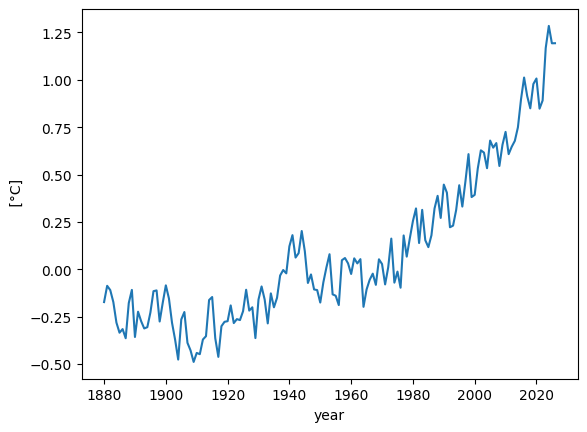

In [ ]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
values = np.column_stack([data[m] for m in months])
print(values.shape)   # (147, 12)

anomaly = xr.DataArray(values, dims=("year", "month"),
                       coords={"year": data["Year"].astype(int), "month": np.arange(1, 13)},
                       attrs={"units": "°C"})
anomaly.mean(dim="month").plot()
plt.show()

In [ ]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"] # création d'une liste
values = np.column_stack([data[m] for m in months])
print(values.shape)   # (147, 12)

anomaly = xr.DataArray(values, dims=("year", "month"),
                       coords={"year": data["Year"].astype(int), "month": np.arange(1, 13)},
                       attrs={"units": "°C"})

(147, 12)


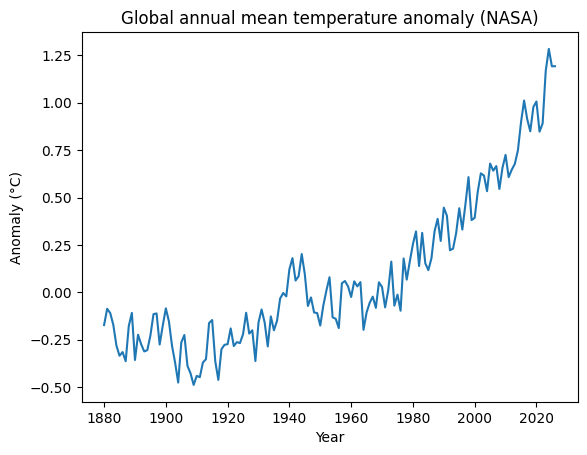

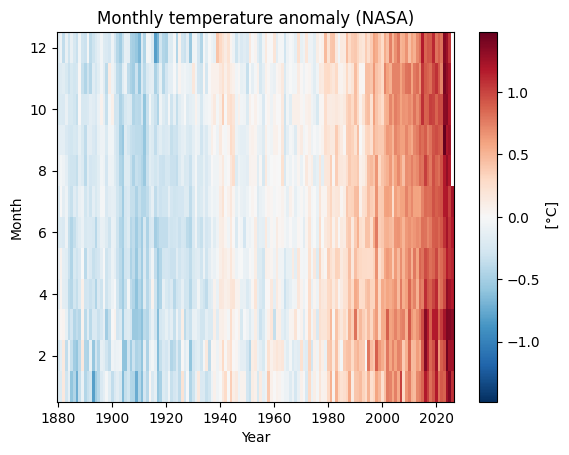

In [ ]:
# Figure 1 : moyenne annuelle (courbe)
annual = anomaly.mean(dim="month")
annual.plot()
plt.title("Global annual mean temperature anomaly (NASA)")
plt.xlabel("Year")
plt.ylabel("Anomaly (°C)")
plt.show()

# Figure 2 : toutes les valeurs, année × mois (carte de couleurs rouge-bleu)
anomaly.plot(x="year")
plt.title("Monthly temperature anomaly (NASA)")
plt.xlabel("Year")
plt.ylabel("Month")
plt.show()

# Comparaison : la courbe annuelle montre la tendance générale, stable jusqu'à
# 1920 environ, puis un réchauffement, surtout depuis 1980 (plus de +1 °C aujourd'hui).
# La carte mois par mois montre que tous les mois se réchauffent (le bleu à
# gauche devient rouge à droite), mais aussi les variations d'un mois à l'autre,
# que la moyenne annuelle ne permet pas de visualiser. Les mois manquants de 2026 apparaissent en blanc.

**Solution et ce que j'ai appris**

En cherchant la cause de l'erreur, j'ai découvert qu'en Python, `...` n'est pas une façon de dire « et ainsi de suite, etc. » : c'est un vrai objet appelé *Ellipsis* (`print(type(...))` qui affiche `<class 'ellipsis'>`).

L'erreur parlait de « size 1 » parce que numpy considère `...` comme une seule valeur, alors que chaque colonne de mois (`data["Jan"]`, `data["Feb"]`, ...) contient 147 valeurs, une par année de 1880 à 2026. `np.column_stack` ne peut pas coller côte à côte des colonnes de longueurs différentes.

Le message indiquait « index 2 », ce qui correspond au troisième élément de ma liste : après `data["Jan"]` (index 0) et `data["Feb"]` (index 1), c'était justement les `...`. Le message d'erreur m'indiquait donc précisément où se trouvait l'erreur dans mon code.

Donc, pour la corriger, j'ai créé une liste `months` contenant les douze mois de janvier à décembre, puis j'ai utilisé `[data[m] for m in months]` pour sélectionner toutes les colonnes. Ensuite, j'ai vérifié que la correction marchait avec `values.shape`, qui donne effectivement `(147, 12)`.

Ce que je retiens de cette erreur : la prochaine fois, je définirai mes mois à l'avance dans une liste comme je l'ai fait, et je ferai attention au signe `...`, qui peut signifier une chose différente en Python. J'ai aussi appris que l'« index » dans un message d'erreur aide à trouver quel élément pose problème rapidement.